# Loan Default Prediction and Approval Policy

**MIT Professional Education, Applied AI and Data Science Program: capstone project (2026)**  
Alex Geiger

A LightGBM model estimates each applicant's probability of default on a home equity loan. A simple cutoff turns that probability into an approve or deny decision, and the decision is valued in dollars against the current process of approving every applicant.

**Contents**

1. Executive summary
2. Problem and solution
3. Recommendations
4. Setup and data
5. Data preparation
6. Model training
7. Feature importance
8. Net revenue threshold analysis
9. Full dataset estimate
10. Current process vs model policy
11. Policy confusion matrix

## 1. Executive Summary

The bank currently approves home equity loans through a manual process, and about 20% of approved loans default. Those defaults cost far more than the interest earned on good loans, so approving high risk applicants holds down net revenue.

The model predicts the probability that an applicant will default. Applicants above a 20% predicted probability are denied and everyone else is approved.

| Metric | Value |
| --- | --- |
| Current net revenue, approving everyone (full dataset) | $10.17M |
| Estimated net revenue with the model policy | $18.30M |
| Estimated uplift | $8.13M |
| Losses avoided on denied loans that would have defaulted | $8.58M |
| Revenue given up on denied loans that would have been repaid | $1.09M |
| Approval rate under the policy (test set) | 77.7% |
| Test AUC / PR-AUC / log loss | 0.971 / 0.908 / 0.180 |

The policy estimate comes from the held-out test set (1,192 loans) scaled to the full 5,960 loans. Most of the gain comes from avoiding losses on loans that would have defaulted, while still approving about 78% of applicants.

The main drivers of default risk were debt-to-income ratio (both its value and whether it was missing), age of the oldest credit line, number of credit lines, prior delinquencies, derogatory reports, recent credit inquiries, loan amount, property value, and mortgage balance.

**Recommended next steps**

- Pilot the model at the three lowest performing branches before any wider rollout.
- Use the 20% cutoff as the policy, with borderline applications (18% to 25%) sent to manual review during the pilot.
- Get legal and compliance sign-off, including how denials are explained to customers.
- Monitor approval rate, default rate, net revenue, fairness, and model drift throughout the pilot, then decide whether to scale.

## 2. Problem and Solution

### The problem

Retail banks earn much of their revenue from loan interest, including home equity loans. When a borrower defaults, the bank loses a large share of the loan. The current approval process is manual and inconsistent, so some applicants with clear warning signs in their credit history are still approved. The result is avoidable default losses.

The goal is to improve approval decisions with a model that predicts whether an applicant is likely to default. Accuracy matters, but the real measure is whether the decisions reduce losses and increase net revenue.

### Proposed solution

The solution is a binary classification model that predicts each applicant's probability of default. Logistic regression and decision trees were evaluated earlier in the program because they are easy to interpret. LightGBM was selected for the final model because it performed better.

The model uses loan amount, mortgage balance, property value, loan purpose, job category, years on the job, credit history (delinquencies, derogatory reports, inquiries, number and age of credit lines), and debt-to-income ratio. Missing value flags are included for each field, since a missing debt-to-income ratio turned out to be a strong signal on its own.

On the held-out test set the model reached an AUC of 0.9709, a PR-AUC of 0.9079, and a log loss of 0.1798, so it separates higher risk applicants from lower risk applicants well.

The probability is turned into a simple policy:

- Predicted default probability of 20% or lower: approve.
- Predicted default probability above 20%: deny.

### Why a 20% cutoff

A threshold analysis compared net revenue across cutoffs from 0% to 100%. The cutoff that maximized net revenue on the training data was 0.371. On the test set, the 20% cutoff produced $3,070.68 of net revenue per applicant, compared with $3,019.63 at 0.371.

The 20% cutoff is also the more conservative choice. It approves fewer high risk loans, and it is easier to raise the cutoff later as pilot results come in than to lower it after losses have occurred. A round number is also easier to explain to branch staff, compliance, and customers.

### Why LightGBM

Credit risk is rarely linear. An applicant may only become high risk when several factors appear together, such as a high debt-to-income ratio, recent inquiries, and prior delinquencies. Boosted trees capture these interactions better than a single decision tree or a logistic regression.

### Business impact

Approving every applicant produces about $10.17M in net revenue across the dataset. With the 20% policy, estimated net revenue rises to about $18.30M, an uplift of about $8.13M.

Any cutoff also denies some applicants who would have repaid. Those denials give up about $1.09M in revenue, but denying the loans that would have defaulted avoids about $8.58M in losses. The policy still approves about 78% of applicants, so it filters out the riskiest loans rather than cutting lending broadly. It should also make decisions more consistent across branches.

## 3. Recommendations

### Implementation

- **Start with a pilot.** Test the model at the three lowest performing branches before rolling it out across the network, so it can be validated on live applications first.
- **Use the 20% cutoff as the policy, with a manual review band.** The policy approves applicants at or below 20% predicted default probability and denies those above 20%. During the pilot, applications between 18% and 25% are sent to a loan officer instead of being decided automatically. Applications below 18% are approved and those above 25% are denied. Comparing the review outcomes with what the 20% rule would have done shows whether the cutoff should move.
- **Get legal and compliance approval before launch.** The model will be used to deny applicants, so the process and the language used to communicate denials must be approved before it goes live.
- **Build a monitoring dashboard with the BI team.** Track approval rate, default rate, net revenue, customer complaints, fairness metrics, and model performance over the course of the pilot.

### Stakeholder actions

| Group | Actions |
| --- | --- |
| Executive leadership | Approve the pilot, agree on success metrics, and decide whether to scale after reviewing results. |
| Data science | Finalize the model pipeline, monitor performance and drift, and review threshold results. |
| Branch managers | Train staff on the new process, make sure it is used consistently, and report issues. |
| Legal and compliance | Review the policy, approve denial language, and check for fairness or regulatory concerns. |
| IT and data teams | Integrate the model into the approval workflow, protect customer data, and support reporting. |
| Finance | Compare pilot results with the current process and track the realized revenue change. |

### Expected benefits and costs

Benefits:

- Fewer approved loans that go on to default, which is the main source of the estimated $8.13M uplift.
- More consistent decisions that are less exposed to human error and bias.
- Faster risk assessment and less staff time spent reviewing every application by hand.

Costs:

- About $0.05M budgeted to run an API that scores applications.
- Revenue given up on denied loans that would have been repaid, estimated at $1,090,320.
- Compliance work to explain model-based denials to customers.

### Risks

- **Selection bias.** The model was trained only on loans that were approved in the past, so it has not seen applicants who were previously denied. This is a main reason for the pilot.
- **Overfitting.** Training AUC reached 1.0, while test AUC was 0.971, PR-AUC 0.908, and log loss 0.180. The test results are strong, but the gap means the model fits the training data very closely. The pilot should monitor whether live performance holds up.
- **Explainability.** LightGBM is harder to explain than logistic regression or a single decision tree. SHAP explanations for individual decisions would help loan officers and compliance understand why an applicant was denied.
- **Fairness and compliance.** The model may affect customer groups differently. Fairness testing is needed before and during the pilot.
- **Customer communication.** Denied applicants need clear, compliant explanations, approved before the model is used for live decisions.
- **Model drift.** Borrower behavior and economic conditions change. The model may need recalibration or retraining if performance declines.

### Further analysis before full rollout

1. Fairness testing across protected groups.
2. Explainability reports, for example with SHAP, so individual decisions can be reviewed and justified.
3. Monitoring of the 20% cutoff during the pilot, using the manual review band to judge whether it should move.

If the pilot confirms the expected improvement, the model can be scaled across the network.

## 4. Setup and Data

In [1]:
import warnings

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FuncFormatter, PercentFormatter

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
)
from lightgbm import LGBMClassifier, log_evaluation

### Data and business assumptions

The data is the public HMEQ home equity dataset: 5,960 past loans with the loan outcome (`BAD` = 1 if the borrower defaulted) and 12 applicant attributes.

The dollar values in this notebook use two assumptions:

| Assumption | Value |
| --- | --- |
| Revenue on an approved loan that is repaid | 22% of the loan amount |
| Loss on an approved loan that defaults | 48.7% of the loan amount |

In [2]:
tbl = pd.read_csv("hmeq.csv")

REVENUE_RATE_NON_DEFAULT = 0.22  # revenue as a share of the loan when it is repaid
LOSS_RATE_DEFAULT = 0.487        # loss as a share of the loan when it defaults
POLICY_THRESHOLD = 0.20          # deny when predicted default probability is above this
LOAN_COL = "Original_Loan"
target_col = "BAD"

print(f"Loans: {len(tbl):,}")
print(f"Default rate: {tbl[target_col].mean():.1%}")

# Keep the raw loan amount for dollar calculations before any transforms
tbl[LOAN_COL] = tbl["LOAN"]

MDL_Features = [
    "LOAN", "MORTDUE", "VALUE", "REASON", "JOB", "YOJ", "DEROG", "DELINQ",
    "CLAGE", "NINQ", "CLNO", "DEBTINC", "MORTDUE_missing_flag",
    "VALUE_missing_flag", "REASON_missing_flag", "JOB_missing_flag",
    "YOJ_missing_flag", "DEROG_missing_flag", "DELINQ_missing_flag",
    "CLAGE_missing_flag", "NINQ_missing_flag", "CLNO_missing_flag",
    "DEBTINC_missing_flag",
]

# Log transform the most skewed columns
log_cols = ["DELINQ", "DEROG", "VALUE", "LOAN"]
tbl[log_cols] = np.log1p(tbl[log_cols])

Loans: 5,960
Default rate: 19.9%


## 5. Data Preparation

### Outliers

Outliers are capped rather than removed, so every loan stays in the data while extreme values have less influence. The bounds use the 20th and 80th percentiles with a 2x multiplier on the range between them. This is wider than the usual 1.5x because the tighter bounds clipped too much information, and LightGBM is fairly robust to outliers. `DEROG` is left uncapped.

In [3]:
# Cap numeric model features at percentile-based bounds instead of dropping rows
numeric_cols = [
    col for col in tbl.select_dtypes(include=["number"]).columns
    if col in MDL_Features
]

outlier_summary = []
tbl_outlier_treated = tbl.copy()

for col in numeric_cols:
    if col == "DEROG":
        continue
    q1 = tbl[col].quantile(0.2)
    q3 = tbl[col].quantile(0.8)
    iqr = q3 - q1
    lower_bound = q1 - 2 * iqr
    upper_bound = q3 + 2 * iqr

    before_outliers = ((tbl[col] < lower_bound) | (tbl[col] > upper_bound)).sum()
    tbl_outlier_treated[col] = tbl[col].clip(lower=lower_bound, upper=upper_bound)

    outlier_summary.append({
        "Variable": col,
        "P20": q1,
        "P80": q3,
        "Range": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Values Capped": before_outliers,
        "Share Capped": before_outliers / len(tbl),
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(
    outlier_summary.style
    .format({
        "P20": "{:,.2f}", "P80": "{:,.2f}", "Range": "{:,.2f}",
        "Lower Bound": "{:,.2f}", "Upper Bound": "{:,.2f}",
        "Values Capped": "{:,.0f}", "Share Capped": "{:.1%}",
    })
    .hide(axis="index")
)

print("Rows before and after capping:", len(tbl), len(tbl_outlier_treated))

Variable,P20,P80,Range,Lower Bound,Upper Bound,Values Capped,Share Capped
LOAN,9.21,10.13,0.92,7.38,11.96,4,0.1%
MORTDUE,"41,657.00","99,280.80","57,623.80","-73,590.60","214,528.40",83,1.4%
VALUE,11.03,11.79,0.77,9.49,13.32,14,0.2%
YOJ,2.00,15.00,13.00,-24.00,41.00,0,0.0%
DELINQ,0.00,0.69,0.69,-1.39,2.08,12,0.2%
CLAGE,105.77,247.09,141.32,-176.87,529.72,20,0.3%
NINQ,0.00,2.00,2.00,-4.00,6.00,121,2.0%
CLNO,13.00,29.00,16.00,-19.00,61.00,11,0.2%
DEBTINC,27.62,39.85,12.23,3.15,64.32,33,0.6%


Rows before and after capping: 5960 5960


### Missing values

Many fields have missing values. Each field gets a flag recording whether it was missing, because missingness itself can carry credit risk signal. The values are then filled based on what each field means:

- **Credit report counts** (`DEROG`, `DELINQ`, `NINQ`) and **years on the job** (`YOJ`): filled with 0, since a missing count most likely means nothing was reported.
- **Categories** (`REASON`, `JOB`): filled with a separate "Missing" category.
- **Financial and credit history fields** (`MORTDUE`, `VALUE`, `CLAGE`, `CLNO`, `DEBTINC`): filled with the median, which is less affected by outliers than the mean.

In [4]:
tbl_clean = tbl_outlier_treated.copy()

cols_with_missing = [
    "MORTDUE", "VALUE", "REASON", "JOB", "YOJ",
    "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC",
]

# Flag missing values before filling anything
for col in cols_with_missing:
    tbl_clean[f"{col}_missing_flag"] = tbl_clean[col].isna().astype(int)

zero_fill_cols = ["DEROG", "DELINQ", "NINQ", "YOJ"]
for col in zero_fill_cols:
    tbl_clean[col] = tbl_clean[col].fillna(0)

tbl_clean["REASON"] = tbl_clean["REASON"].fillna("Missing")
tbl_clean["JOB"] = tbl_clean["JOB"].fillna("Missing")

median_fill_cols = ["MORTDUE", "VALUE", "CLAGE", "CLNO", "DEBTINC"]
for col in median_fill_cols:
    tbl_clean[col] = tbl_clean[col].fillna(tbl_clean[col].median())

print("Shape before:", tbl.shape)
print("Shape after: ", tbl_clean.shape)
print("Missing values remaining in model features:", int(tbl_clean[MDL_Features].isna().sum().sum()))

Shape before: (5960, 14)
Shape after:  (5960, 25)
Missing values remaining in model features: 0


## 6. Model Training

1. **Prepare the data.** `REASON` and `JOB` are stored as categories so LightGBM can use them directly.
2. **Split train and test (80/20).** The split is stratified on the default flag and on whether `DEROG` and `VALUE` were missing, so both sets have the same mix of outcomes and missing data patterns.
3. **Train LightGBM.** The hyperparameters below are the final values from a cross-validated search. The search code is not included to keep the notebook short.
4. **Evaluate on the test set** with AUC, PR-AUC, and log loss. Training AUC is shown for comparison.

In [5]:
RANDOM_STATE = 42
TEST_SIZE = 0.20
CAT_COLS = ["REASON", "JOB"]

# Stratify on the target and two missing data patterns
STRAT_COLS = [target_col, "DEROG_missing_flag", "VALUE_missing_flag"]

data = tbl_clean.copy()
for col in CAT_COLS:
    data[col] = data[col].astype("category")

y = data[target_col]
strat_key = data[STRAT_COLS].astype(str).agg("_".join, axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    data,
    y,
    test_size=TEST_SIZE,
    stratify=strat_key,
    random_state=RANDOM_STATE,
)

# Final tuned settings from cross-validation
model = LGBMClassifier(
    objective="binary",
    boosting_type="gbdt",
    n_estimators=1114,
    learning_rate=0.020,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=45,
    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,
    reg_alpha=0.10,
    reg_lambda=1.25,
    importance_type="gain",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1,
)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*categorical.*")
    warnings.filterwarnings("ignore", message=".*Overriding.*")
    warnings.filterwarnings("ignore", message=".*eval_set.*")

    model.fit(
        X_train[MDL_Features],
        y_train,
        eval_set=[(X_train[MDL_Features], y_train)],
        eval_names=["training"],
        eval_metric="auc",
        callbacks=[log_evaluation(period=100)],
    )

train_pred = model.predict_proba(X_train[MDL_Features])[:, 1]
test_pred = model.predict_proba(X_test[MDL_Features])[:, 1]

print("\nTraining AUC:", f"{roc_auc_score(y_train, train_pred):.4f}")
print("\nTest set performance")
print(f"AUC:      {roc_auc_score(y_test, test_pred):.4f}")
print(f"PR-AUC:   {average_precision_score(y_test, test_pred):.4f}")
print(f"Log loss: {log_loss(y_test, np.clip(test_pred, 1e-15, 1 - 1e-15)):.4f}")

[100]	training's auc: 0.953574	training's binary_logloss: 0.244003
[200]	training's auc: 0.979027	training's binary_logloss: 0.171083
[300]	training's auc: 0.990725	training's binary_logloss: 0.129284
[400]	training's auc: 0.996346	training's binary_logloss: 0.100922
[500]	training's auc: 0.998623	training's binary_logloss: 0.0809028
[600]	training's auc: 0.999581	training's binary_logloss: 0.0657765
[700]	training's auc: 0.999888	training's binary_logloss: 0.0544799
[800]	training's auc: 0.999982	training's binary_logloss: 0.0457164
[900]	training's auc: 0.999999	training's binary_logloss: 0.038799
[1000]	training's auc: 1	training's binary_logloss: 0.0332127
[1100]	training's auc: 1	training's binary_logloss: 0.0286938

Training AUC: 1.0000

Test set performance
AUC:      0.9709
PR-AUC:   0.9079
Log loss: 0.1798


## 7. Feature Importance

Gain importance measures how much each feature improved the model's splits. Values are shown as a percent of total gain, for every feature the model used.

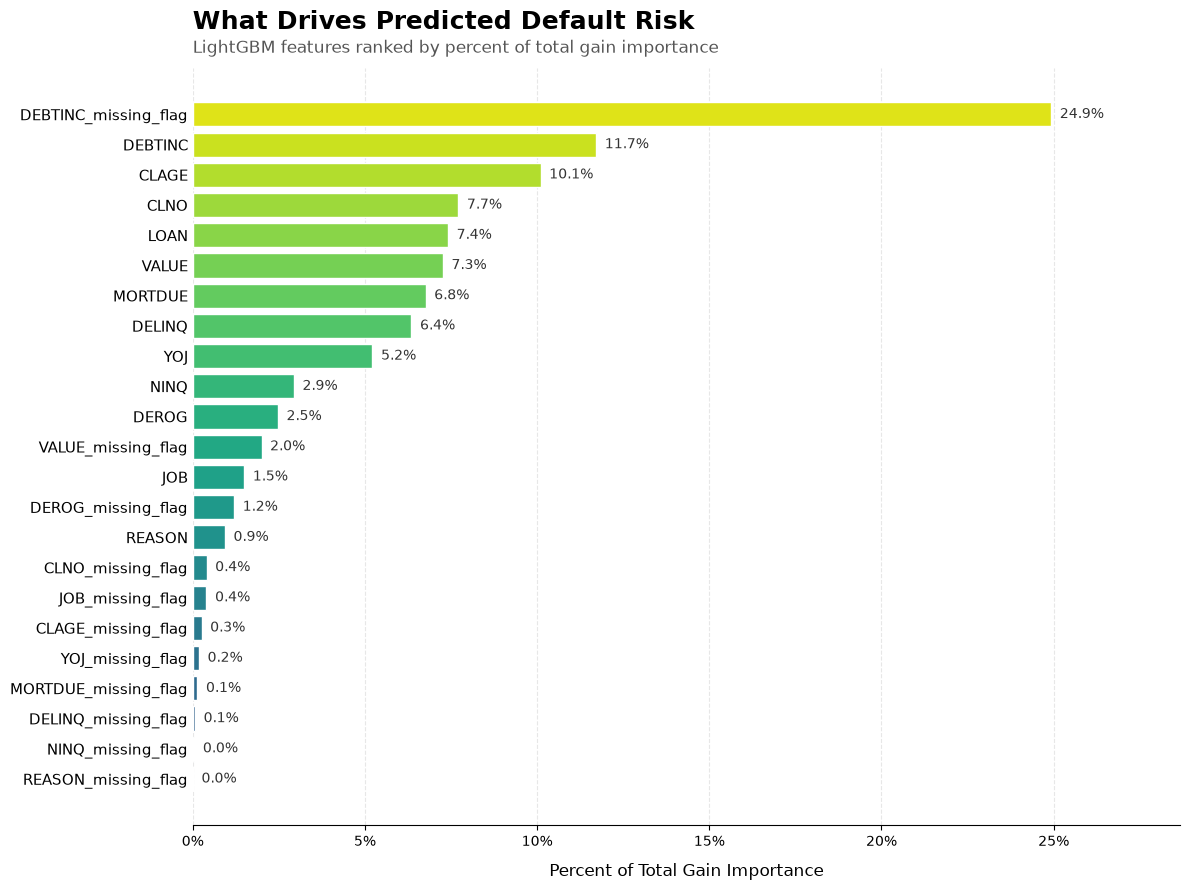

In [6]:
feature_importance = (
    pd.DataFrame({
        "Feature": X_train[MDL_Features].columns,
        "Importance": model.feature_importances_,
    })
    .query("Importance > 0")
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
feature_importance["Importance %"] = (
    feature_importance["Importance"] / feature_importance["Importance"].sum() * 100
)

plot_data = feature_importance.sort_values("Importance %", ascending=True)
colors = cm.viridis(np.linspace(0.25, 0.95, len(plot_data)))

fig, ax = plt.subplots(figsize=(12, 9))
bars = ax.barh(plot_data["Feature"], plot_data["Importance %"], color=colors, edgecolor="white")

ax.set_title("What Drives Predicted Default Risk", fontsize=18, fontweight="bold", loc="left", pad=28)
ax.text(0, 1.02, "LightGBM features ranked by percent of total gain importance",
        transform=ax.transAxes, fontsize=12, color="#555555")
ax.set_xlabel("Percent of Total Gain Importance", fontsize=12, labelpad=10)
ax.set_ylabel("")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Label each bar with its value
max_value = plot_data["Importance %"].max()
for bar, value in zip(bars, plot_data["Importance %"]):
    ax.text(value + max_value * 0.01, bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%", va="center", fontsize=10, color="#333333")

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.tick_params(axis="y", length=0, labelsize=11)
ax.set_xlim(0, max_value * 1.15)

plt.tight_layout()
plt.show()

## 8. Net Revenue Threshold Analysis

For each cutoff from 0 to 1, loans at or below the cutoff are approved. Net revenue is the revenue from approved loans that are repaid minus the losses on approved loans that default.

The training data is used to find the cutoff with the highest net revenue per applicant, so the test set is not used to pick it. The training-optimized cutoff and the 20% policy are then both applied to the test set for comparison.

In [7]:
def net_revenue_curve(X, y, pred_prob, thresholds):
    """Net revenue for each approval cutoff (approve if pred_prob <= cutoff)."""
    y = np.asarray(y).astype(int)
    loan = X[LOAN_COL]
    rows = []

    for t in thresholds:
        approve = pred_prob <= t
        approved_good = approve & (y == 0)
        approved_bad = approve & (y == 1)

        revenue = REVENUE_RATE_NON_DEFAULT * loan[approved_good].sum()
        loss = LOSS_RATE_DEFAULT * loan[approved_bad].sum()
        net_revenue = revenue - loss

        rows.append({
            "threshold": t,
            "approved_loans": approve.sum(),
            "approval_rate": approve.mean(),
            "approved_defaults": approved_bad.sum(),
            "approved_non_defaults": approved_good.sum(),
            "revenue_from_non_defaults": revenue,
            "loss_from_defaults": loss,
            "net_revenue": net_revenue,
            "avg_net_revenue_per_customer": net_revenue / len(y),
        })

    return pd.DataFrame(rows)


train_prob = model.predict_proba(X_train[MDL_Features])[:, 1]
test_prob = model.predict_proba(X_test[MDL_Features])[:, 1]
thresholds = np.linspace(0, 1, 1001)

train_curve = net_revenue_curve(X_train, y_train, train_prob, thresholds)
test_curve = net_revenue_curve(X_test, y_test, test_prob, thresholds)

# Best cutoff on the training data
train_best = train_curve.loc[train_curve["avg_net_revenue_per_customer"].idxmax()]
optimal_train_threshold = train_best["threshold"]

# Results at the 20% policy cutoff, and the training-optimized cutoff on test
train_policy = train_curve.iloc[(train_curve["threshold"] - POLICY_THRESHOLD).abs().argmin()]
test_policy = test_curve.iloc[(test_curve["threshold"] - POLICY_THRESHOLD).abs().argmin()]
test_at_train_optimal = test_curve.iloc[
    (test_curve["threshold"] - optimal_train_threshold).abs().argmin()
]


def summary_row(dataset, label, threshold, r):
    return {
        "Dataset": dataset,
        "Cutoff": label,
        "Threshold": threshold,
        "Total Net Revenue": r["net_revenue"],
        "Net Revenue per Applicant": r["avg_net_revenue_per_customer"],
        "Approval Rate": r["approval_rate"],
        "Approved Loans": r["approved_loans"],
        "Approved Defaults": r["approved_defaults"],
        "Approved Non-Defaults": r["approved_non_defaults"],
    }


threshold_summary = pd.DataFrame([
    summary_row("Train", "Training-optimized", optimal_train_threshold, train_best),
    summary_row("Train", "20% policy", POLICY_THRESHOLD, train_policy),
    summary_row("Test", "Training-optimized", optimal_train_threshold, test_at_train_optimal),
    summary_row("Test", "20% policy", POLICY_THRESHOLD, test_policy),
])

print(f"Training-optimized threshold: {optimal_train_threshold:.3f}")
print(f"Policy threshold:             {POLICY_THRESHOLD:.3f}")

display(
    threshold_summary.style
    .format({
        "Threshold": "{:.3f}",
        "Total Net Revenue": "${:,.0f}",
        "Net Revenue per Applicant": "${:,.2f}",
        "Approval Rate": "{:.1%}",
        "Approved Loans": "{:,.0f}",
        "Approved Defaults": "{:,.0f}",
        "Approved Non-Defaults": "{:,.0f}",
    })
    .hide(axis="index")
)

Training-optimized threshold: 0.371
Policy threshold:             0.200


Dataset,Cutoff,Threshold,Total Net Revenue,Net Revenue per Applicant,Approval Rate,Approved Loans,Approved Defaults,Approved Non-Defaults
Train,Training-optimized,0.371,"$15,862,638","$3,326.90",80.1%,"3,817",0,"3,817"
Train,20% policy,0.200,"$15,789,114","$3,311.48",79.5%,"3,789",0,"3,789"
Test,Training-optimized,0.371,"$3,599,395","$3,019.63",80.6%,961,46,915
Test,20% policy,0.200,"$3,660,255","$3,070.68",77.7%,926,32,894


### Net revenue by cutoff

The shaded area is the 18% to 25% manual review band proposed for the pilot.

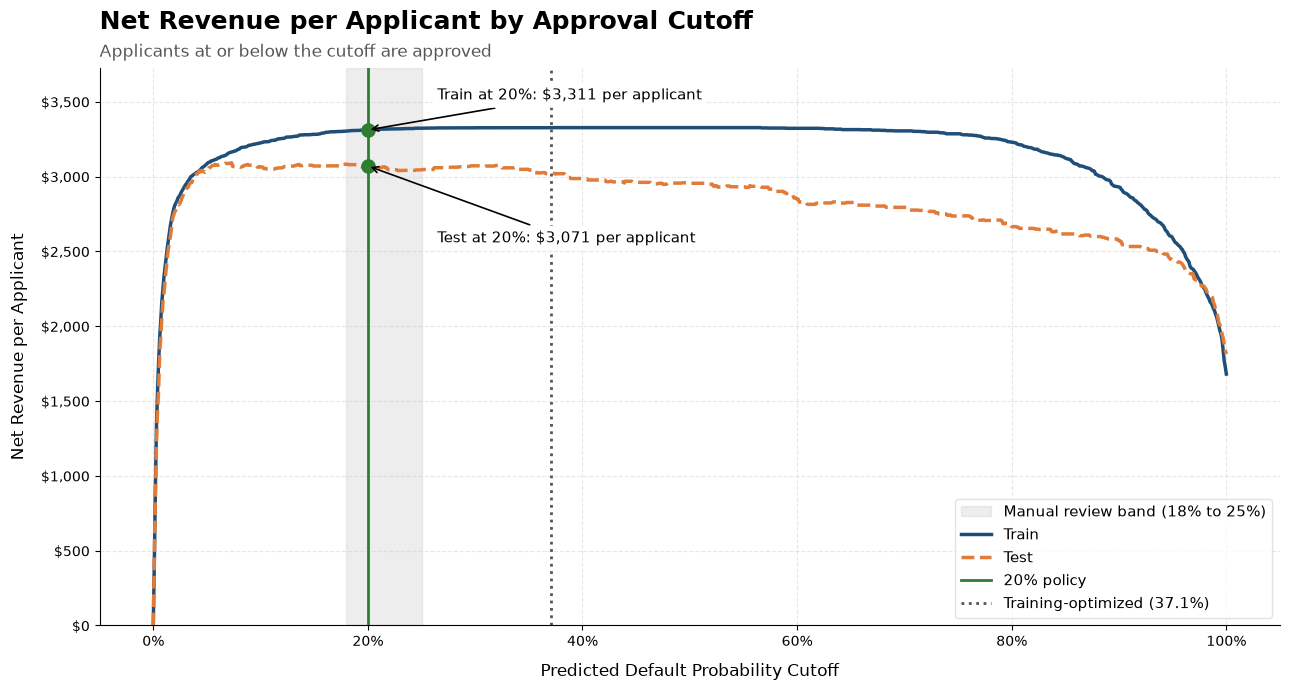

In [8]:
fig, ax = plt.subplots(figsize=(13, 7))

ax.axvspan(0.18, 0.25, color="#cccccc", alpha=0.35, label="Manual review band (18% to 25%)")

ax.plot(train_curve["threshold"], train_curve["avg_net_revenue_per_customer"],
        linewidth=2.5, color="#1f4e79", label="Train")
ax.plot(test_curve["threshold"], test_curve["avg_net_revenue_per_customer"],
        linewidth=2.5, linestyle="--", color="#e07b39", label="Test")

ax.axvline(POLICY_THRESHOLD, linewidth=2, color="#2e7d32", label="20% policy")
ax.axvline(optimal_train_threshold, linewidth=2, linestyle=":", color="#555555",
           label=f"Training-optimized ({optimal_train_threshold:.1%})")

# Mark and label the policy results
for r, name, offset in [(train_policy, "Train", (50, 22)), (test_policy, "Test", (50, -55))]:
    value = r["avg_net_revenue_per_customer"]
    ax.scatter(POLICY_THRESHOLD, value, s=90, color="#2e7d32", zorder=5)
    ax.annotate(f"{name} at 20%: ${value:,.0f} per applicant",
                xy=(POLICY_THRESHOLD, value), xytext=offset, textcoords="offset points",
                fontsize=11, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none"), zorder=6,
                arrowprops=dict(arrowstyle="->", lw=1.2))

ax.set_title("Net Revenue per Applicant by Approval Cutoff", fontsize=18, fontweight="bold", loc="left", pad=28)
ax.text(0, 1.02, "Applicants at or below the cutoff are approved",
        transform=ax.transAxes, fontsize=12, color="#555555")
ax.set_xlabel("Predicted Default Probability Cutoff", fontsize=12, labelpad=10)
ax.set_ylabel("Net Revenue per Applicant", fontsize=12, labelpad=10)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.set_ylim(0, train_curve["avg_net_revenue_per_customer"].max() * 1.12)
ax.legend(frameon=True, facecolor="white", edgecolor="#dddddd", fontsize=11, loc="lower right")

plt.tight_layout()
plt.show()

## 9. Full Dataset Estimate

The 20% policy is applied to the test set, and the results are scaled to the full dataset:

- Scale factor = loans in the full dataset / loans in the test set
- Net revenue = revenue from approved loans that are repaid minus losses on approved loans that default

The table also shows the cost of the denials (revenue given up on good loans) and their benefit (losses avoided on loans that would have defaulted).

In [9]:
test_default_prob = model.predict_proba(X_test[MDL_Features])[:, 1]
test_actual_bad = np.asarray(y_test).astype(int)
test_loan_amount = X_test[LOAN_COL]

# Apply the policy and split loans into outcome groups
approve_test = test_default_prob <= POLICY_THRESHOLD
approved_non_default = approve_test & (test_actual_bad == 0)
approved_default = approve_test & (test_actual_bad == 1)

denied_test = ~approve_test
denied_non_default = denied_test & (test_actual_bad == 0)
denied_default = denied_test & (test_actual_bad == 1)

# Revenue and loss on approved loans
revenue_from_non_defaults = REVENUE_RATE_NON_DEFAULT * test_loan_amount[approved_non_default].sum()
loss_from_defaults = LOSS_RATE_DEFAULT * test_loan_amount[approved_default].sum()
test_net_revenue = revenue_from_non_defaults - loss_from_defaults

# Revenue given up and losses avoided on denied loans
missed_revenue_from_denied_good_loans = REVENUE_RATE_NON_DEFAULT * test_loan_amount[denied_non_default].sum()
loss_avoided_from_denied_defaults = LOSS_RATE_DEFAULT * test_loan_amount[denied_default].sum()
net_value_of_denials = loss_avoided_from_denied_defaults - missed_revenue_from_denied_good_loans

# Scale to the full dataset
test_n = len(y_test)
full_n = len(tbl_clean.dropna(subset=[target_col]))
scale_factor = full_n / test_n


def policy_column(scale):
    return {
        "Applicants": test_n * scale,
        "Approved Loans": approve_test.sum() * scale,
        "Approval Rate": approve_test.mean(),
        "Approved Non-Defaults": approved_non_default.sum() * scale,
        "Approved Defaults": approved_default.sum() * scale,
        "Denied Loans": denied_test.sum() * scale,
        "Denied Non-Defaults": denied_non_default.sum() * scale,
        "Denied Defaults": denied_default.sum() * scale,
        "Revenue from Approved Non-Defaults USD": revenue_from_non_defaults * scale,
        "Loss from Approved Defaults USD": loss_from_defaults * scale,
        "Net Revenue USD": test_net_revenue * scale,
        "Missed Revenue from Denied Good Loans USD": missed_revenue_from_denied_good_loans * scale,
        "Loss Avoided from Denied Defaults USD": loss_avoided_from_denied_defaults * scale,
        "Net Value of Denials USD": net_value_of_denials * scale,
        "Net Revenue per Applicant USD": test_net_revenue / test_n,
        "Net Revenue per Approved Loan USD": test_net_revenue / max(approve_test.sum(), 1),
    }


extrapolation_summary = pd.DataFrame({
    "Test Set Actual": policy_column(1),
    f"Full Dataset Estimate (x{scale_factor:.0f})": policy_column(scale_factor),
})


def fmt_value(metric, v):
    if metric == "Approval Rate":
        return f"{v:.1%}"
    if "per" in metric:
        return f"${v:,.2f}"
    if metric.endswith("USD"):
        return f"${v:,.0f}"
    return f"{v:,.0f}"


display(extrapolation_summary.apply(lambda col: [fmt_value(m, v) for m, v in col.items()]))

,Test Set Actual,Full Dataset Estimate (x5)
Applicants,"1,192","5,960"
Approved Loans,926,"4,630"
Approval Rate,77.7%,77.7%
Approved Non-Defaults,894,"4,470"
Approved Defaults,32,160
Denied Loans,266,"1,330"
Denied Non-Defaults,60,300
Denied Defaults,206,"1,030"
Revenue from Approved Non-Defaults USD,"$3,891,580","$19,457,900"
Loss from Approved Defaults USD,"$231,325","$1,156,625"


## 10. Current Process vs Model Policy

Today every loan is approved, so the approval rate is 100%. Revenue comes from loans that are repaid and losses come from loans that default.

Across the full dataset, the current process produces about $10.17M in net revenue. The model policy is estimated at about $18.30M, an uplift of about $8.13M.

In [10]:
full_data = tbl_clean.dropna(subset=[target_col]).copy()
today_actual_bad = full_data[target_col].astype(int).to_numpy()
today_loan_amount = pd.to_numeric(full_data[LOAN_COL], errors="coerce").fillna(0).to_numpy()

# Current process: every applicant is approved
approve_today = np.ones(len(full_data), dtype=bool)
deny_today = ~approve_today

today_approved_non_default = approve_today & (today_actual_bad == 0)
today_approved_default = approve_today & (today_actual_bad == 1)
today_denied_non_default = deny_today & (today_actual_bad == 0)  # zero today
today_denied_default = deny_today & (today_actual_bad == 1)      # zero today

today_revenue_from_non_defaults = REVENUE_RATE_NON_DEFAULT * today_loan_amount[today_approved_non_default].sum()
today_loss_from_defaults = LOSS_RATE_DEFAULT * today_loan_amount[today_approved_default].sum()
today_net_revenue = today_revenue_from_non_defaults - today_loss_from_defaults

today_missed_revenue_from_denied_good_loans = REVENUE_RATE_NON_DEFAULT * today_loan_amount[today_denied_non_default].sum()
today_loss_avoided_from_denied_defaults = LOSS_RATE_DEFAULT * today_loan_amount[today_denied_default].sum()
today_net_value_of_denials = today_loss_avoided_from_denied_defaults - today_missed_revenue_from_denied_good_loans

# Model policy estimate from the previous section
policy = extrapolation_summary.iloc[:, 1]
policy_net_revenue = policy["Net Revenue USD"]
policy_missed_revenue = policy["Missed Revenue from Denied Good Loans USD"]
policy_loss_avoided = policy["Loss Avoided from Denied Defaults USD"]
policy_net_value_denials = policy["Net Value of Denials USD"]
estimated_uplift = policy_net_revenue - today_net_revenue

comparison_summary = pd.DataFrame([
    {
        "Scenario": "Current process (approve all)",
        "Approval Rate": approve_today.mean(),
        "Net Revenue": today_net_revenue,
        "Uplift vs Current": 0,
        "Missed Revenue from Denied Good Loans": today_missed_revenue_from_denied_good_loans,
        "Loss Avoided from Denied Defaults": today_loss_avoided_from_denied_defaults,
        "Net Value of Denials": today_net_value_of_denials,
    },
    {
        "Scenario": "Model policy (20% cutoff)",
        "Approval Rate": policy["Approval Rate"],
        "Net Revenue": policy_net_revenue,
        "Uplift vs Current": estimated_uplift,
        "Missed Revenue from Denied Good Loans": policy_missed_revenue,
        "Loss Avoided from Denied Defaults": policy_loss_avoided,
        "Net Value of Denials": policy_net_value_denials,
    },
])

display(
    comparison_summary.style
    .format({
        "Approval Rate": "{:.1%}",
        "Net Revenue": "${:,.0f}",
        "Uplift vs Current": "${:,.0f}",
        "Missed Revenue from Denied Good Loans": "${:,.0f}",
        "Loss Avoided from Denied Defaults": "${:,.0f}",
        "Net Value of Denials": "${:,.0f}",
    })
    .hide(axis="index")
)

print(f"Current net revenue (full dataset):    ${today_net_revenue:,.2f}")
print(f"Model policy net revenue (estimate):   ${policy_net_revenue:,.2f}")
print(f"Estimated uplift:                      ${estimated_uplift:,.2f}")
print(f"Revenue given up on denied good loans: ${policy_missed_revenue:,.2f}")
print(f"Losses avoided on denied defaults:     ${policy_loss_avoided:,.2f}")
print(f"Net value of denials:                  ${policy_net_value_denials:,.2f}")

Scenario,Approval Rate,Net Revenue,Uplift vs Current,Missed Revenue from Denied Good Loans,Loss Avoided from Denied Defaults,Net Value of Denials
Current process (approve all),100.0%,"$10,173,647",$0,$0,$0,$0
Model policy (20% cutoff),77.7%,"$18,301,275","$8,127,628","$1,090,320","$8,581,427","$7,491,107"


Current net revenue (full dataset):    $10,173,647.20
Model policy net revenue (estimate):   $18,301,275.00
Estimated uplift:                      $8,127,627.80
Revenue given up on denied good loans: $1,090,320.00
Losses avoided on denied defaults:     $8,581,427.00
Net value of denials:                  $7,491,107.00


## 11. Policy Confusion Matrix (Test Set)

This shows how the 20% policy's decisions line up with what actually happened on the 1,192 test loans.

- **Approved** = predicted to repay
- **Denied** = predicted to default
- **Good** = actually repaid
- **Bad** = actually defaulted

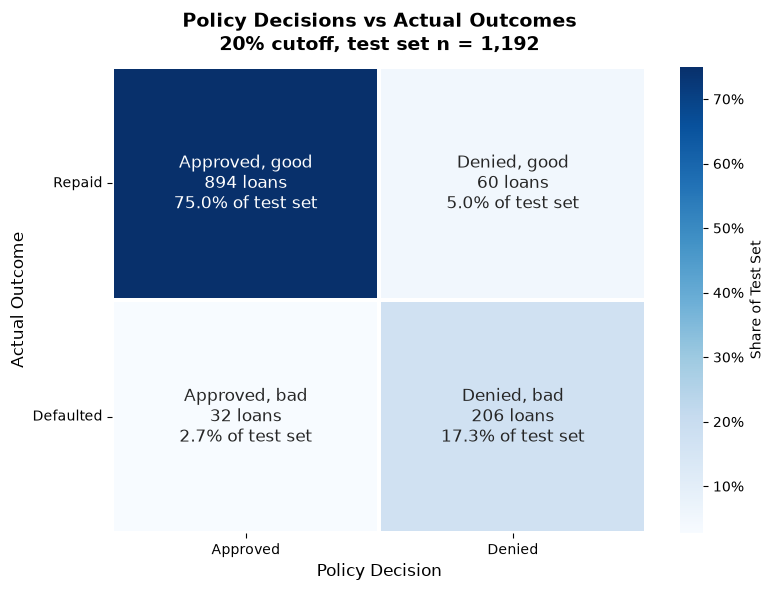

In [11]:
# Rows are the actual outcome, columns are the policy decision (1 = deny)
test_pred_bad = (test_default_prob > POLICY_THRESHOLD).astype(int)
cm_counts = confusion_matrix(test_actual_bad, test_pred_bad, labels=[0, 1])
cm_pct = cm_counts / cm_counts.sum()

names = [["Approved, good", "Denied, good"], ["Approved, bad", "Denied, bad"]]
labels = np.array([
    [f"{names[i][j]}\n{cm_counts[i, j]:,} loans\n{cm_pct[i, j]:.1%} of test set" for j in range(2)]
    for i in range(2)
])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm_pct,
    annot=labels,
    fmt="",
    cmap="Blues",
    linewidths=1.5,
    linecolor="white",
    cbar_kws={"label": "Share of Test Set", "format": PercentFormatter(xmax=1, decimals=0)},
    annot_kws={"fontsize": 12},
    ax=ax,
)

ax.set_title(f"Policy Decisions vs Actual Outcomes\n20% cutoff, test set n = {cm_counts.sum():,}",
             fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Policy Decision", fontsize=12)
ax.set_ylabel("Actual Outcome", fontsize=12)
ax.set_xticklabels(["Approved", "Denied"])
ax.set_yticklabels(["Repaid", "Defaulted"], rotation=0)

plt.tight_layout()
plt.show()